# Calculate and add conduite size on the nodes of graph 

The size is calculated from splays or from left-right-up-down information

## Splay

If splay information exists on the nodes, then an approximation of the geometry of the conduit at the node (distance from the node to the wall) can be calculated.
This calculation is performed by projecting the splays to the plan perpendicular to the direction of conduit at this point. The direction of the conduit is assumed to be perpendicular to the bisectrice of the angle formed by the conduit before and after the node.

The cross-sectional dimensions are calculated based on the projected splay lengths in the u and v directions, 
which are perpendicular to the conduit direction at each node. Different outputs can be requested, 
including the geometric mean of the cross-section radius, the cross-section width and height, 
and the projected splay lengths in the u and v directions. The function returns a dictionary 
with the requested geometric properties for each node in the graph. 

The cross-sectional dimensions are calculated as follows:

- The cross-sectional width is calculated as the difference between the maximum and minimum projected splay lengths in the u direction.
- The cross-sectional height is calculated as the difference between the maximum and minimum projected splay lengths in the v direction.
- The geometric mean of the cross-section radius is calculated as the square root of the product of half the cross-section width and half the cross-section height.  

### Some caveats to consider:

- Depending on the survey data, some nodes may have no splays or only one splay, which can result in zero cross-sectional dimensions or biased estimates. 
- The splay measurements may not be uniformly distributed around the node, which can also affect the accuracy of the cross-sectional dimensions. 
- Some cavers measure splays in the front and back of the station, sometime far away from the station and the projection of those splays may not 
be representative of the actual cross-section.
- For nodes with degree greater than 2 (intersections), the cross-sectional dimensions are  calculated as 
the mean of the projected splay lengths, rather than the projections in the u and v directions. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import sys
import os

# to import karstnet from the src folder for developpement purpose
sys.path.append("../src")
import karstnet as kn

# Load some data and create a graph
path_to_yaml = '../data/006_ReveEveille_000/006_ReveEveille_000.yaml' # '../data/047_Seefeldhoele_000/047_Seefeldhoele_000.yaml'
G = kn.io_func.networkx_from_yaml(path_to_yaml)
print(f'List of node attributes attached to the graph: {kn.utils.get_node_attribute_names(G)}')


List of node attributes attached to the graph: ['fulladdress', 'flags', 'csdim', 'pos', 'splays', 'idsql', 'comments']


In [2]:
#extract and calculate all geometry information
csdim = kn.geom.calc_conduit_dimensions(G, output = 'csdim')
geommean_radius = kn.geom.calc_conduit_dimensions(G, output = 'geometric_mean')
cs_width = kn.geom.calc_conduit_dimensions(G, output = 'cs_width')
cs_height = kn.geom.calc_conduit_dimensions(G, output = 'cs_height')
radius_u_positive, radius_u_negative, radius_v_positive, radius_v_negative = kn.geom.calc_conduit_dimensions(G, output = 'plotting_radius')

In [3]:
#ADD GEOMETRY INFO ON THE NODES
nx.set_node_attributes(G, geommean_radius, 'geommean_radius') 
nx.set_node_attributes(G, cs_width, 'width') 
nx.set_node_attributes(G, cs_height, 'height') 
nx.set_node_attributes(G, csdim, 'csdim') 

begin Nina's stuff

In [4]:
conduit_directions, u_vectors, v_vectors = kn.geom.get_conduit_direction(G)
splay_vectors = kn.geom.get_splay_vectors(G)
projected_splay_lengths_u, projected_splay_lengths_v = kn.geom.calc_projected_splay_lengths(G)
pos3d = kn.utils.get_pos3d(G, pos_attr='pos')

In [5]:
print(f'length of u dict: {len(u_vectors.keys())}')
print(f'length of v dict: {len(v_vectors.keys())}')

assert np.allclose( [np.linalg.norm(u) for u in u_vectors.values()], 1), "not all u vectors are unitary"
assert np.allclose( [np.linalg.norm(v) for v in v_vectors.values()], 1), "not all v vectors are unitary"

print(f'length of splay vectors dict: {len(splay_vectors.keys())}')
print(f'length of horizontal splay projections dict: {len(projected_splay_lengths_u.keys())}')
print(f'length of vertical-ish splay projections dict: {len(projected_splay_lengths_v.keys())}')

print(f'length of node positions dict: {len(pos3d.keys())}')

print(f'length of radius_u_positive dict: {len(radius_u_positive.keys())}')



length of u dict: 77
length of v dict: 77
length of splay vectors dict: 77
length of horizontal splay projections dict: 77
length of vertical-ish splay projections dict: 77
length of node positions dict: 78
length of radius_u_positive dict: 76


In [6]:
for key in radius_u_positive.keys():
    print(f'key {key}:')
    print(f'number of splays: {len(splay_vectors[key])}')
    print(f'max projected splay length: {np.max(projected_splay_lengths_u[key])}')
    print(f"min projected splay length: {np.min(projected_splay_lengths_u[key])}")
    print(f"positive radius: {radius_u_positive[key]}")
    print(f"negative radius: {radius_u_negative[key]}")
    print('------------')

key 66:
number of splays: 1
max projected splay length: 0.005419646688829882
min projected splay length: 0.005419646688829882
positive radius: 0.005419646688829882
negative radius: 0.0
------------
key 3:
number of splays: 27
max projected splay length: 0.02076028372809624
min projected splay length: -3.359722867086494
positive radius: 0.02076028372809624
negative radius: -3.359722867086494
------------
key 74:
number of splays: 25
max projected splay length: 1.7423899564549048
min projected splay length: -3.283291271545547
positive radius: 1.7423899564549048
negative radius: -3.283291271545547
------------
key 17:
number of splays: 18
max projected splay length: 1.3781912938481726
min projected splay length: -4.704479956323674
positive radius: 1.3781912938481726
negative radius: -4.704479956323674
------------
key 11:
number of splays: 36
max projected splay length: 5.159608814541255
min projected splay length: -2.092717002813385
positive radius: 5.159608814541255
negative radius: -2.

In [7]:
splays_quiver=np.array([np.concatenate((pos3d[key], vector)) for key, vectors in splay_vectors.items() for vector in vectors])
upos_quiver=np.array([np.concatenate((pos3d[key], u_vectors[key]*length)) for key, length in radius_u_positive.items() ])
uneg_quiver=np.array([np.concatenate((pos3d[key], u_vectors[key]*length)) for key, length in radius_u_negative.items()])

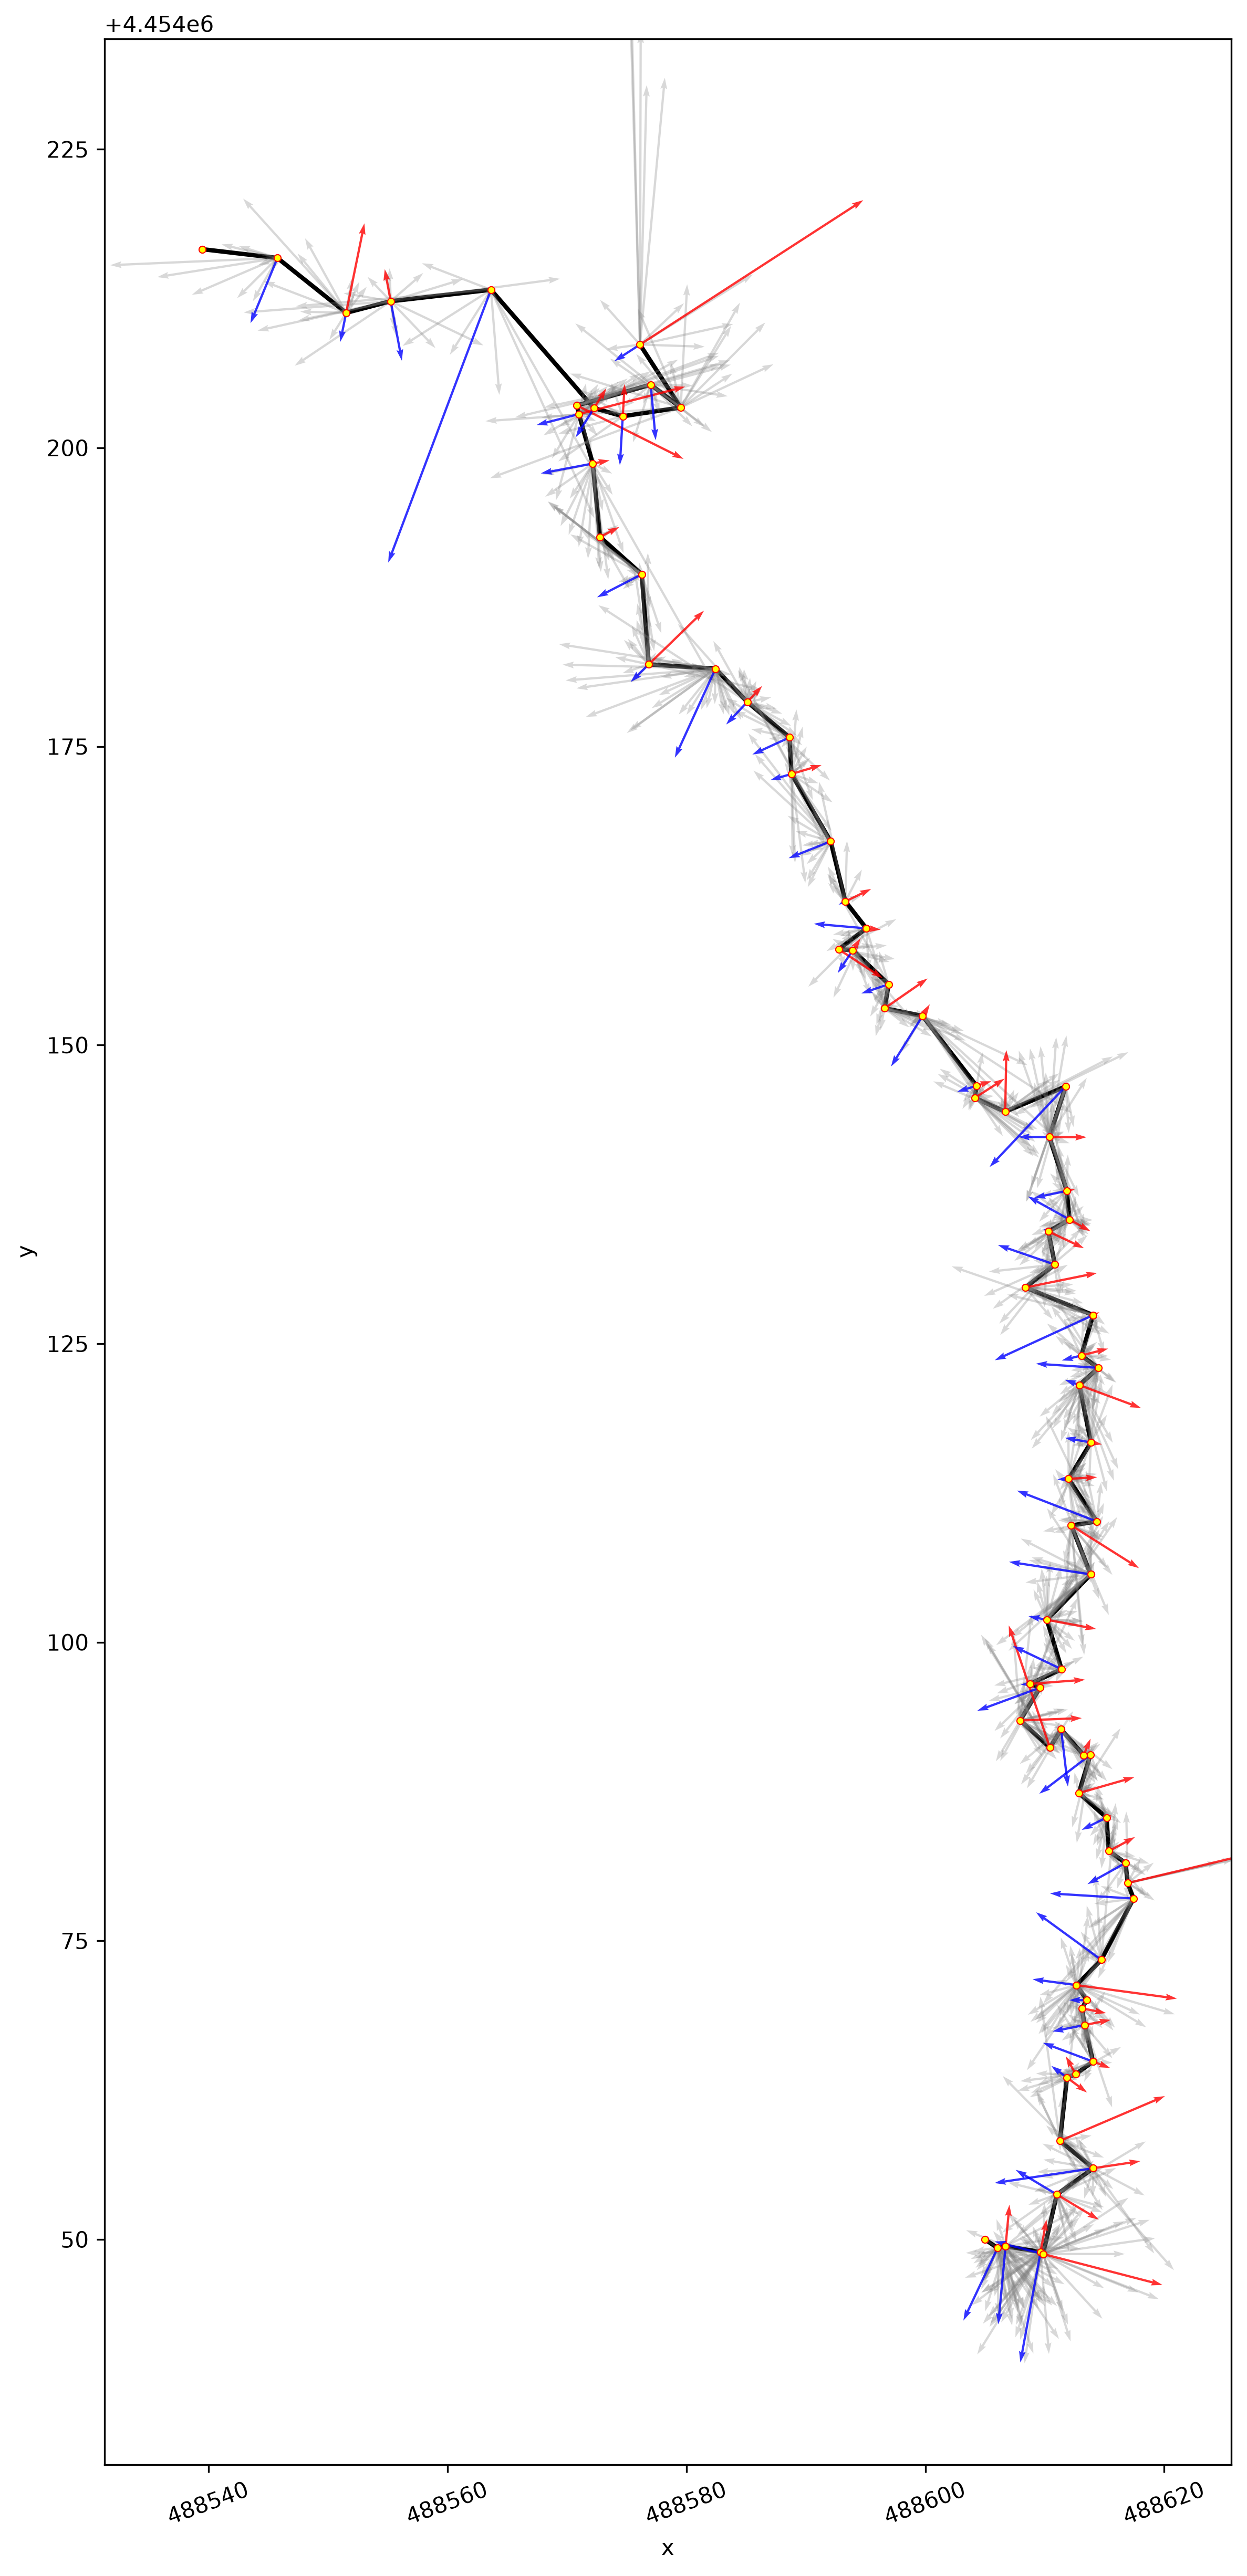

In [12]:
# Plot 2D (no node / edge property) - projection onto Oxy (default)
options = {
    'node_size'   : 10,          # node size
    'linewidths'  : 0.5,         # node border width       
    'edgecolors'  : 'red',       # node border color
    'node_color'  : 'yellow', # node color
    'width'       : 2,           # edge width
    'edge_color'  : 'black',      # edge color
    'with_labels' : False,       # show node labels ?
    # 'font_size'   : 10           # font size for labels
}

fig, ax = plt.subplots(figsize=(20,20),dpi=300)

kn.view.plot_graph2d(
    G,
    plot_nodes=True, # default is True; set to False to hide nodes
    plot_edges=True, # default is True; set to False to hide edges
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)

ax.set_aspect('equal')
ax.quiver(splays_quiver[:, 0], splays_quiver[:, 1], splays_quiver[:, 3], splays_quiver[:, 4], color='grey', alpha=0.3, angles='xy', scale_units='xy', scale=.5, width=0.002)
ax.quiver(upos_quiver[:, 0], upos_quiver[:, 1], upos_quiver[:, 3], upos_quiver[:, 4], color='red', alpha=0.8, angles='xy', scale_units='xy', scale=.5, width=0.002)
ax.quiver(uneg_quiver[:, 0], uneg_quiver[:, 1], uneg_quiver[:, 3], uneg_quiver[:, 4], color='blue', alpha=0.8, angles='xy', scale_units='xy', scale=.5, width=0.002)

plt.show()

end Nina's stuff

In [9]:
conduit_directions, u_vectors, v_vectors = kn.geom.get_conduit_direction(G)
projected_splay_vectors = kn.geom.get_splay_vectors(G)
projected_splay_lengths_u, projected_splay_lengths_v = kn.geom.calc_projected_splay_lengths(G)
splay_vectors = kn.geom.get_splay_vectors(G)



In [10]:
pos3d = kn.utils.get_pos3d(G, pos_attr='pos')
pos_x = np.array([float(pos3d[key][0]) for key, arrays in splay_vectors.items() for _ in arrays])
pos_y = np.array([float(pos3d[key][1]) for key, arrays in splay_vectors.items() for _ in arrays])
pos_z = np.array([float(pos3d[key][2]) for key, arrays in splay_vectors.items() for _ in arrays])

splay_vectors = kn.geom.get_splay_vectors(G)
# list_splay_vec =[value for key, value in projected_splay_vectors.items()]
# list_keys =[key for key, value in projected_splay_vectors.items()]
sx = np.array([float(arr[0]) for arrays in splay_vectors.values() for arr in arrays])
sy = np.array([float(arr[1]) for arrays in splay_vectors.values() for arr in arrays])
sz = np.array([float(arr[2]) for arrays in splay_vectors.values() for arr in arrays])

#---------------------------------------

# projected_splays_u = [value*cs_width[key]/2 for key, value in u_vectors.items() if key in cs_width]
# projected_splays_v = [value*cs_height[key]/2 for key, value in v_vectors.items() if key in cs_height]
projected_splays_u = {key: np.asarray(value) for key, value in u_vectors.items() if key in cs_width}
projected_splays_v = {key: np.asarray(value) for key, value in v_vectors.items() if key in cs_height}

# node positions for the nodes where projection was possible (nodes degree 2)
pos_x_proj = np.array([float(pos3d[key][0]) for key in projected_splays_u.keys()])
pos_y_proj = np.array([float(pos3d[key][1]) for key in projected_splays_u.keys()])
pos_z_proj = np.array([float(pos3d[key][2]) for key in projected_splays_u.keys()])

# ux = np.array([float(arrays[0]) for arrays in projected_splays_u])
ux_positive = np.array([float(arrays[0]*radius_u_positive[key]) for key,arrays in projected_splays_u.items()])
uy_positive =  np.array([float(arrays[1]*radius_u_positive[key]) for key,arrays in projected_splays_u.items()])
uz_positive =  np.array([float(arrays[2]*radius_u_positive[key]) for key,arrays in projected_splays_u.items()])

# ux = np.array([float(arrays[0]) for arrays in projected_splays_u])
ux_negative = np.array([float(arrays[0]*radius_u_negative[key]) for key,arrays in projected_splays_u.items()])
uy_negative =  np.array([float(arrays[1]*radius_u_negative[key]) for key,arrays in projected_splays_u.items()])
uz_negative =  np.array([float(arrays[2]*radius_u_negative[key]) for key,arrays in projected_splays_u.items()])

# # ux = np.array([float(arrays[0]) for arrays in projected_splays_u])
# vx_positive = np.array([float(arrays[0]) for key,arrays in projected_splays_v.items()])
# vy_positive =  np.array([float(arrays[1]) for key,arrays in projected_splays_v.items()])
# vz_positive =  np.array([float(arrays[2]) for key,arrays in projected_splays_v.items()])

# # ux = np.array([float(arrays[0]) for arrays in projected_splays_u])
# vx_negative = np.array([float(arrays[0]) for key,arrays in projected_splays_v.items()])
# vy_negative =  np.array([float(arrays[1]) for key,arrays in projected_splays_v.items()])
# vz_negative =  np.array([float(arrays[2]) for key,arrays in projected_splays_v.items()])


# node positions for the nodes where projection was possible (nodes degree 2)
pos_x_dir = np.array([float(pos3d[key][0]) for key,array in conduit_directions.items() if list(array) != []])
pos_y_dir = np.array([float(pos3d[key][1]) for key,array in conduit_directions.items() if list(array) != []])
pos_z_dir = np.array([float(pos3d[key][2]) for key,array in conduit_directions.items() if list(array) != []])

conduit_direction_x = np.array([float(array[0]) for array in conduit_directions.values() if list(array) != []])
conduit_direction_y = np.array([float(array[1]) for array in conduit_directions.values() if list(array) != []])
conduit_direction_z = np.array([float(array[2]) for array in conduit_directions.values() if list(array) != []])




# projected_splays_u = u_vectors*-cs_width

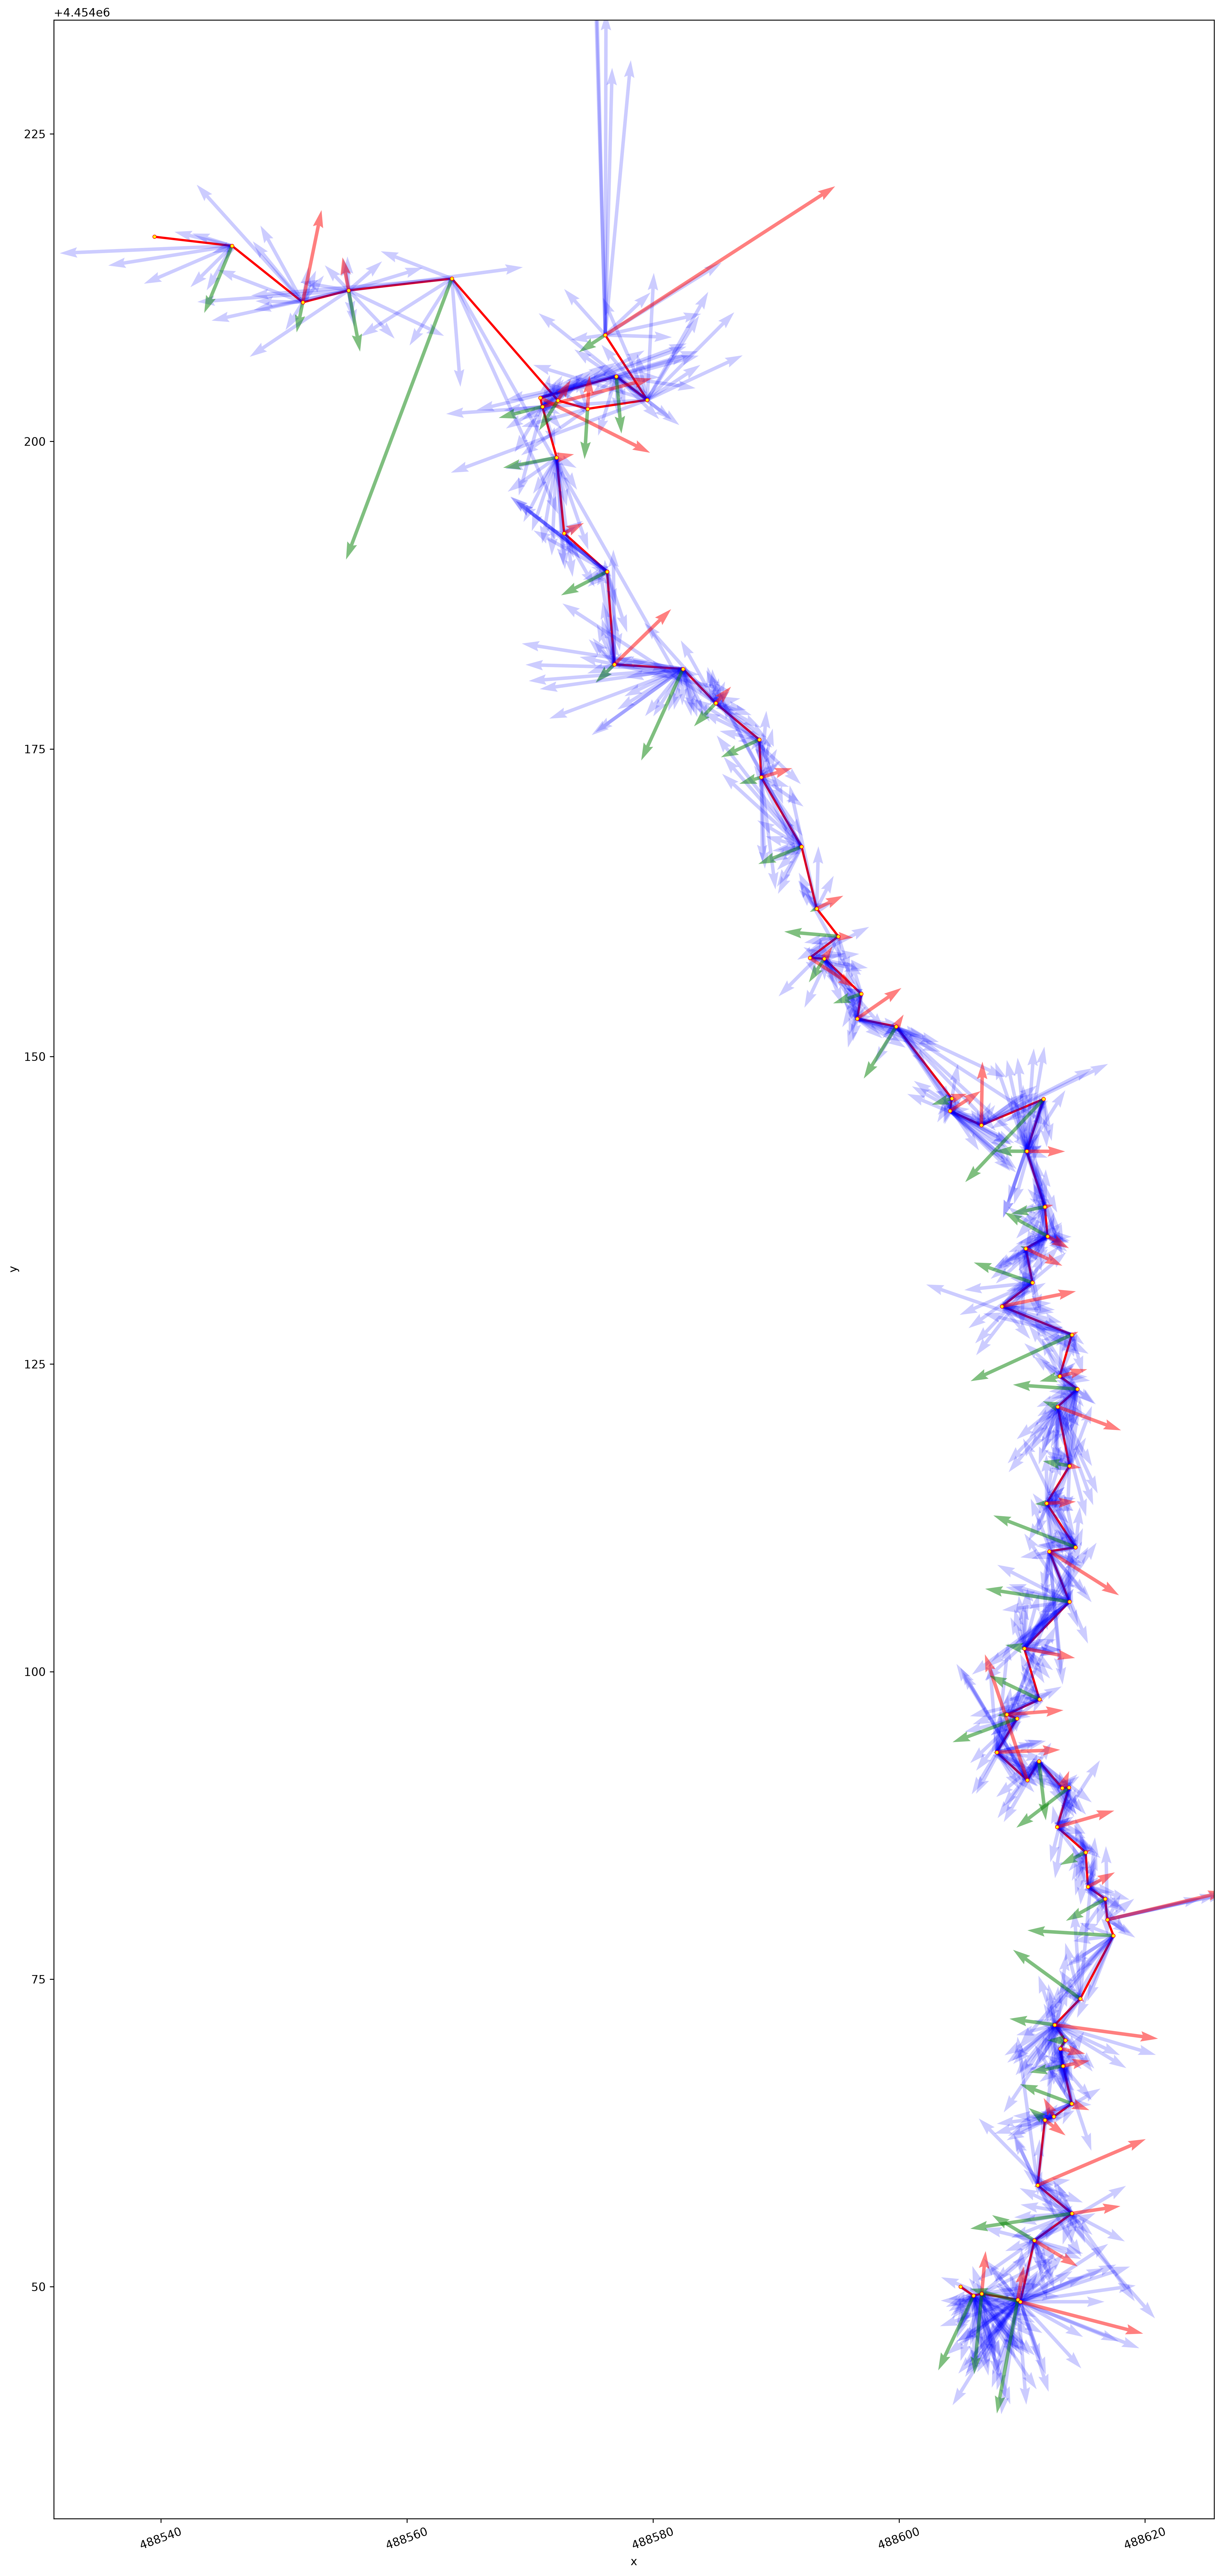

In [13]:
# Plot 2D (no node / edge property) - projection onto Oxy (default)
options = {
    'node_size'   : 10,          # node size
    'linewidths'  : 0.5,         # node border width       
    'edgecolors'  : 'red',       # node border color
    'node_color'  : 'yellow', # node color
    'width'       : 2,           # edge width
    'edge_color'  : 'red',      # edge color
    'with_labels' : False,       # show node labels ?
    # 'font_size'   : 10           # font size for labels
}

fig, ax = plt.subplots(figsize=(50,40),dpi=300)

kn.view.plot_graph2d(
    G,
    plot_nodes=True, # default is True; set to False to hide nodes
    plot_edges=True, # default is True; set to False to hide edges
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options
)

ax.quiver(pos_x, pos_y, sx, sy, color='blue', alpha=0.2, angles='xy', scale_units='xy', scale=.5, width=0.003)
ax.quiver(pos_x_proj, pos_y_proj, ux_positive, uy_positive, color='red', alpha=0.5, angles='xy', scale_units='xy', scale=.5, width=0.003)
ax.quiver(pos_x_proj, pos_y_proj, ux_negative, uy_negative, color='green', alpha=0.5, angles='xy', scale_units='xy', scale=.5, width=0.003)
# ax.quiver(pos_x_proj, pos_y_proj, vx, vy, color='red', alpha=0.5)
# ax.quiver(pos_x_proj, pos_y_proj, -vx, -vy, color='red', alpha=0.5)
#cax.quiver(pos_x_dir, pos_y_dir, conduit_direction_x, conduit_direction_y, width=0.002)
ax.set_aspect('equal')

plt.show()

In [14]:

direction = kn.geom.get_conduit_direction(G)
direction

({66: array([-0.50573787,  0.34679168,  0.78991439]),
  3: array([ 0.34451401, -0.16223859, -0.92465601]),
  74: array([ 0.45271392, -0.04220958, -0.8906562 ]),
  17: array([ 0.39040523, -0.07145426, -0.91786603]),
  11: array([ 0.14096736,  0.54305647, -0.82777888]),
  6: array([ 0.42693573,  0.71207842, -0.55737798]),
  7: array([-0.11037085,  0.7351714 , -0.66883577]),
  58: array([-0.36268829,  0.85019102, -0.38161818]),
  2: array([ 0.50765131,  0.68134475, -0.52731346]),
  16: array([ 0.76758613,  0.42104649, -0.48325086]),
  72: array([ 0.30094322,  0.80455344, -0.51198335]),
  57: array([-0.18024348,  0.90524245, -0.38477058]),
  49: array([ 0.18513703,  0.93406622, -0.30535975]),
  44: array([ 0.00290532,  0.91134296, -0.41163768]),
  59: array([ 0.12604107,  0.9397533 , -0.31776939]),
  20: array([ 0.58641948,  0.80493976, -0.09046645]),
  65: array([ 0.06146709,  0.99806527, -0.00935479]),
  46: array([-0.23000184,  0.96773961,  0.10285522]),
  39: array([-0.47593096,  0.855

In [15]:
projected_splays =kn.geom.get_projected_splay_vectors(G)
projected_splays

AttributeError: module 'karstnet.geom' has no attribute 'get_projected_splay_vectors'

In [ ]:
splay_u,splay_v = kn.geom.calc_conduit_dimensions(G, output = 'projections')

In [ ]:
splays_direction = kn.geom.get_projected_splay_direction(G)

In [ ]:
splays_direction

In [ ]:
cs_dimension = kn.geom.calc_conduit_dimensions(G, output = 'csdim')
cs_dimension = {k: v for k, v in cs_dimension.items() if not (v[0] == 0 and v[1] == 0)}
nx.set_node_attributes(G, cs_dimension, 'csdim') 

In [ ]:
cs_dimension_lrud = kn.geom.calc_csdim_from_th(G,)
#remove node with 0 with and 0 height:
cs_dimension_lrud = {k: v for k, v in cs_dimension_lrud.items() if not (v[0] == 0 and v[1] == 0)}
nx.set_node_attributes(G, cs_dimension_lrud, 'csdim')  